## ============================================================
## STEP 1 — Import the toolkit
## ============================================================

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

In [3]:
# Silence non-critical warnings so real errors stay visible
warnings.filterwarnings("ignore")

# Make every plot readable by default
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.titlesize"] = 13

## ============================================================
## STEP 2 — Load raw CSV and understand the shape before touching it
## ============================================================

In [5]:
RAW_PATH = "S&P 500 Stock Prices 2014-2017.csv"

# parse_dates converts the text "2014-01-02" into a real datetime
df_raw = pd.read_csv(RAW_PATH, parse_dates=["date"])

In [6]:
print(f"Rows            : {len(df_raw):,}")


Rows            : 497,472


In [7]:
print(f"Columns         : {list(df_raw.columns)}")


Columns         : ['symbol', 'date', 'open', 'high', 'low', 'close', 'volume']


In [8]:
print(f"Unique symbols  : {df_raw['symbol'].nunique()}")


Unique symbols  : 505


In [9]:
print(f"Unique dates    : {df_raw['date'].nunique()}")


Unique dates    : 1007


In [10]:
print(f"Date range      : {df_raw['date'].min().date()} → {df_raw['date'].max().date()}")


Date range      : 2014-01-02 → 2017-12-29


In [11]:
print(f"Dtypes:\n{df_raw.dtypes}")



Dtypes:
symbol            object
date      datetime64[ns]
open             float64
high             float64
low              float64
close            float64
volume             int64
dtype: object


In [12]:
df_raw.head()

,symbol,date,open,high,low,close,volume
0,AAL,2014-01-02,25.0700,25.8200,25.0600,25.3600,8998943
1,AAPL,2014-01-02,79.3828,79.5756,78.8601,79.0185,58791957
2,AAP,2014-01-02,110.3600,111.8800,109.2900,109.7400,542711
3,ABBV,2014-01-02,52.1200,52.3300,51.5200,51.9800,4569061
4,ABC,2014-01-02,70.1100,70.2300,69.4800,69.8900,1148391


## ============================================================
## STEP 2.1 — Data quality scan (do this BEFORE cleaning)
## ============================================================

In [13]:
# 1) Missing values — one column at a time
missing = df_raw.isnull().sum()
print("\nMissing values:")
print(missing[missing > 0] if missing.sum() else "  None")


Missing values:
open    11
high     8
low      8
dtype: int64


In [14]:
# 2) Duplicates — complete rows AND (symbol, date) pairs
print(f"\nFull duplicate rows           : {df_raw.duplicated().sum()}")
print(f"Duplicate (symbol, date) pairs: {df_raw.duplicated(subset=['symbol','date']).sum()}")


Full duplicate rows           : 0
Duplicate (symbol, date) pairs: 0


In [15]:
# 3) Non-positive prices — always report, never stay silent
print("\nNon-positive price check:")
for c in ["open", "high", "low", "close"]:
    bad = int((df_raw[c] <= 0).sum())
    print(f"  {c:<6} : {bad}")


Non-positive price check:
  open   : 0
  high   : 0
  low    : 0
  close  : 0


In [16]:
# 4) OHLC relationship violations (only counted where all four exist)
#    NOTE: NaN rows are excluded here on purpose — they get caught by
#    the missing-values check above, and NaN <= comparison is always False.
valid_ohlc = df_raw.dropna(subset=["open", "high", "low", "close"])

print("\nOHLC rule violations (NaN-free rows only):")
print(f"  high < low                : {(valid_ohlc['high'] < valid_ohlc['low']).sum()}")
print(f"  open outside [low, high]  : {((valid_ohlc['open'] > valid_ohlc['high']) | (valid_ohlc['open'] < valid_ohlc['low'])).sum()}")
print(f"  close outside [low, high] : {((valid_ohlc['close'] > valid_ohlc['high']) | (valid_ohlc['close'] < valid_ohlc['low'])).sum()}")


OHLC rule violations (NaN-free rows only):
  high < low                : 1
  open outside [low, high]  : 4
  close outside [low, high] : 9


In [17]:
# 4b) Show the offending rows so we can eyeball them
bad_ohlc = valid_ohlc[
    (valid_ohlc["high"] < valid_ohlc["low"]) |
    (~valid_ohlc["open"].between(valid_ohlc["low"], valid_ohlc["high"])) |
    (~valid_ohlc["close"].between(valid_ohlc["low"], valid_ohlc["high"]))
]
print(f"\nTotal rows violating OHLC rules: {len(bad_ohlc)}")
print(bad_ohlc[["symbol", "date", "open", "high", "low", "close"]])


Total rows violating OHLC rules: 12
       symbol       date     open      high      low     close
45501     AOS 2014-05-19   23.890   23.5950   23.850   24.4450
45548     CHD 2014-05-19   18.770   33.9525   33.695   33.8950
48774     SPG 2014-05-28  176.230  176.6000  174.500  165.4200
59618     CHK 2014-06-30   30.430   31.1000   30.370   29.3900
60252      IP 2014-07-01   50.850   51.0700   50.570   50.0900
79814       O 2014-08-27   44.675   44.7000   44.660   44.5272
103984    DHR 2014-11-06   78.470   81.3050   80.490   81.2600
104196      O 2014-11-06   44.740   47.5700   46.730   46.8600
269985    BBY 2016-03-14   33.550   33.7500   33.080   32.7200
291756    WRK 2016-05-13   42.450   42.8900   41.820   38.3900
293543    LNT 2016-05-19   35.190   35.7850   35.085   17.8700
301166     UA 2016-06-10   35.750   36.4100   35.700   35.5400


In [18]:
# 5) Volume problems
print(f"\nZero-volume rows     : {(df_raw['volume'] == 0).sum()}")
print(f"Negative-volume rows : {(df_raw['volume'] < 0).sum()}")


Zero-volume rows     : 4
Negative-volume rows : 0


In [19]:
# 6) Alphabet GOOG anomaly — one stray row, remember for cleaning
print(f"\nGOOG  rows  : {(df_raw['symbol'] == 'GOOG').sum()}   (single-row anomaly)")
print(f"GOOGL rows  : {(df_raw['symbol'] == 'GOOGL').sum()}")


GOOG  rows  : 949   (single-row anomaly)
GOOGL rows  : 1007


## ============================================================
## STEP 3 — Clean the data
## ============================================================

In [20]:
# Always work on a copy. df_raw stays untouched — we can always
# prove what we started from.
df = df_raw.copy()

In [21]:
# 3.1 — Drop duplicates. A symbol should have exactly one row per trading day.
df = df.drop_duplicates(subset=["symbol", "date"])

In [22]:
# 3.2 — Drop rows missing any OHLC or volume field.
#       We could impute, but fill with averages distorts real price
#       analysis. It's safer to drop these ~27 rows out of 497K.
df = df.dropna(subset=["symbol", "date", "open", "high", "low", "close", "volume"])

In [23]:
# 3.3 — Keep only physically-valid records
df = df[
    (df[["open", "high", "low", "close"]] > 0).all(axis=1) &
    (df["volume"] >= 0)
]

In [24]:
# 3.4 — Enforce the OHLC rule: low <= open/close <= high
df = df[
    (df["high"] >= df["low"]) &
    (df["open"].between(df["low"], df["high"])) &
    (df["close"].between(df["low"], df["high"]))
]

In [25]:
# 3.5 — Remove the single stray GOOG row.
#       GOOG and GOOGL are the same company; one row of GOOG would
#       pollute every per-symbol aggregation (volatility, MA, return).
df = df[df["symbol"] != "GOOG"]

In [26]:
# 3.5b — Sanity: after cleaning, counts should match the scan
print(f"Symbols after cleaning : {df['symbol'].nunique()}")           # expect 504
print(f"Nulls in OHLCV         : {df[['open','high','low','close','volume']].isnull().sum().sum()}")
print(f"Non-positive prices    : {(df[['open','high','low','close']] <= 0).sum().sum()}")
print(f"OHLC violations left   : {((df['high'] < df['low']) |
                                  (~df['open'].between(df['low'], df['high'])) |
                                  (~df['close'].between(df['low'], df['high']))).sum()}")

Symbols after cleaning : 504
Nulls in OHLCV         : 0
Non-positive prices    : 0
OHLC violations left   : 0


In [27]:
# 3.6 — Sort chronologically per symbol.
#       MANDATORY — shift(1) and rolling() depend on row order.
df = df.sort_values(["symbol", "date"]).reset_index(drop=True)

# Report how much we dropped
print(f"\nRaw rows   : {len(df_raw):,}")
print(f"Clean rows : {len(df):,}")
print(f"Removed    : {len(df_raw) - len(df):,}  ({(1 - len(df)/len(df_raw))*100:.2f}%)")


Raw rows   : 497,472
Clean rows : 496,500
Removed    : 972  (0.20%)


## ============================================================
## STEP 4 — Feature engineering (build in dependency order)
## ============================================================

In [28]:
# Order matters:
#   prev_close → returns → ranges/gaps → MA → volatility
#   → volume → calendar → flags → risk

# 4.1 — Previous closing price PER SYMBOL
#       groupby is critical: without it, shift(1) leaks AAPL's price
#       into the row above AAL.
df["prev_close"] = df.groupby("symbol")["close"].shift(1)

In [29]:
# 4.2 — Return & change metrics
df["day_over_day_change"] = df["close"] - df["prev_close"]           # $ change vs yesterday
df["intraday_change"]     = df["close"] - df["open"]                  # $ change same day
# modern pandas does NOT forward-fill by default — no fill_method arg needed
df["daily_return_pct"]    = df.groupby("symbol")["close"].pct_change() * 100
df["intraday_change_pct"] = (df["close"] - df["open"]) / df["open"] * 100

In [30]:
# 4.3 — Intraday range + opening gap
df["intraday_range"]     = df["high"] - df["low"]
df["intraday_range_pct"] = df["intraday_range"] / df["open"] * 100
df["gap_pct"]            = (df["open"] - df["prev_close"]) / df["prev_close"] * 100

In [31]:
# 4.4 — Moving averages (7 / 30 / 50 sessions)
#       min_periods=window keeps early rows NaN instead of
#       averaging 2 values on day 2.
for w in (7, 30, 50):
    df[f"ma_{w}"] = df.groupby("symbol")["close"].transform(
        lambda s, w=w: s.rolling(w, min_periods=w).mean()
    )

In [32]:
# 4.5 — Rolling volatility (std of daily returns)
for w in (7, 30):
    df[f"volatility_{w}d"] = df.groupby("symbol")["daily_return_pct"].transform(
        lambda s, w=w: s.rolling(w, min_periods=w).std()
    )

In [33]:
# 4.6 — Volume metrics
df["avg_volume_30d"]  = df.groupby("symbol")["volume"].transform(
    lambda s: s.rolling(30, min_periods=30).mean()
)
# replace(0, np.nan) prevents inf from division-by-zero
df["relative_volume"] = df["volume"] / df["avg_volume_30d"].replace(0, np.nan)

In [34]:
# 4.7 — Calendar columns (make SQL GROUP BY and Power BI slicers easy)
df["year"]       = df["date"].dt.year
df["month"]      = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()
df["quarter"]    = "Q" + df["date"].dt.quarter.astype(str)
df["day_name"]   = df["date"].dt.day_name()

In [35]:
# 4.8 — Categorical flags
df["daily_status"] = np.select(
    [df["daily_return_pct"] > 0, df["daily_return_pct"] < 0],
    ["Positive", "Negative"],
    default="First Observation",
)
df["trend_status"] = np.select(
    [df["close"] > df["ma_30"], df["close"] < df["ma_30"]],
    ["Above 30-Day MA", "Below 30-Day MA"],
    default="Insufficient History",
)

In [36]:
# 4.9 — Risk metrics
#       running_peak = highest close so far
#       drawdown     = how far below that peak we are (always <= 0)
df["running_peak"] = df.groupby("symbol")["close"].cummax()
df["drawdown_pct"] = (df["close"] - df["running_peak"]) / df["running_peak"] * 100
df["rolling_return_30d"] = df.groupby("symbol")["close"].transform(
    lambda s: (s / s.shift(30) - 1) * 100
)

In [37]:
print(f"Final shape : {df.shape}")
print(f"New columns : {df.shape[1] - df_raw.shape[1]}")
print(f"Columns     : {list(df.columns)}")
df.head()

Final shape : (496500, 32)
New columns : 25
Columns     : ['symbol', 'date', 'open', 'high', 'low', 'close', 'volume', 'prev_close', 'day_over_day_change', 'intraday_change', 'daily_return_pct', 'intraday_change_pct', 'intraday_range', 'intraday_range_pct', 'gap_pct', 'ma_7', 'ma_30', 'ma_50', 'volatility_7d', 'volatility_30d', 'avg_volume_30d', 'relative_volume', 'year', 'month', 'month_name', 'quarter', 'day_name', 'daily_status', 'trend_status', 'running_peak', 'drawdown_pct', 'rolling_return_30d']


,symbol,date,open,high,low,close,volume,prev_close,day_over_day_change,intraday_change,...,year,month,month_name,quarter,day_name,daily_status,trend_status,running_peak,drawdown_pct,rolling_return_30d
0,A,2014-01-02,57.10,57.100,56.15,56.21,1916160,NaN,NaN,-0.89,...,2014,1,January,Q1,Thursday,First Observation,Insufficient History,56.21,0.000000,NaN
1,A,2014-01-03,56.39,57.345,56.26,56.92,1866651,56.21,0.71,0.53,...,2014,1,January,Q1,Friday,Positive,Insufficient History,56.92,0.000000,NaN
2,A,2014-01-06,57.40,57.700,56.56,56.64,1777472,56.92,-0.28,-0.76,...,2014,1,January,Q1,Monday,Negative,Insufficient History,56.92,-0.491918,NaN
3,A,2014-01-07,56.95,57.630,56.93,57.45,1463208,56.64,0.81,0.50,...,2014,1,January,Q1,Tuesday,Positive,Insufficient History,57.45,0.000000,NaN
4,A,2014-01-08,57.33,58.540,57.17,58.39,2659468,57.45,0.94,1.06,...,2014,1,January,Q1,Wednesday,Positive,Insufficient History,58.39,0.000000,NaN


In [41]:
print(f"Columns         : {list(df.columns)}")

Columns         : ['symbol', 'date', 'open', 'high', 'low', 'close', 'volume', 'prev_close', 'day_over_day_change', 'intraday_change', 'daily_return_pct', 'intraday_change_pct', 'intraday_range', 'intraday_range_pct', 'gap_pct', 'ma_7', 'ma_30', 'ma_50', 'volatility_7d', 'volatility_30d', 'avg_volume_30d', 'relative_volume', 'year', 'month', 'month_name', 'quarter', 'day_name', 'daily_status', 'trend_status', 'running_peak', 'drawdown_pct', 'rolling_return_30d']


## ============================================================
## STEP 5 — Sanity check BEFORE exporting anywhere
## ============================================================

In [38]:
# 5.1 — Dates are chronologically ordered per stock?
is_sorted = df.groupby("symbol")["date"].apply(
    lambda s: s.is_monotonic_increasing
).all()
print(f"Dates sorted per symbol : {is_sorted}")

Dates sorted per symbol : True


In [39]:
# 5.2 — NaN counts should match warm-up windows
#       For a 30-day MA, the first 30 rows of EACH stock are NaN.
#       Real expected = sum(min(window, rows_that_stock_has))
per_symbol = df.groupby("symbol").size()
n = df["symbol"].nunique()

real_expected = {
    "prev_close":       n,
    "daily_return_pct": n,
    "ma_7":             int(per_symbol.clip(upper=7).sum()),
    "ma_30":            int(per_symbol.clip(upper=30).sum()),
    "ma_50":            int(per_symbol.clip(upper=50).sum()),
    "volatility_7d":    int(per_symbol.clip(upper=7).sum()),
    "volatility_30d":   int(per_symbol.clip(upper=30).sum()),
    "avg_volume_30d":   int(per_symbol.clip(upper=30).sum()),
    "relative_volume":  int(per_symbol.clip(upper=30).sum()),
}
print("\nWarm-up NaN check (tolerance ±5):")
for col, exp in real_expected.items():
    act = int(df[col].isna().sum())
    flag = "OK" if abs(act - exp) <= 5 else "MISMATCH"
    print(f"  {col:<18} expected={exp:>7,}  actual={act:>7,}  {flag}")


Warm-up NaN check (tolerance ±5):
  prev_close         expected=    504  actual=    504  OK
  daily_return_pct   expected=    504  actual=    504  OK
  ma_7               expected=  3,528  actual=  3,024  MISMATCH
  ma_30              expected= 15,108  actual= 14,605  MISMATCH
  ma_50              expected= 25,168  actual= 24,665  MISMATCH
  volatility_7d      expected=  3,528  actual=  3,528  OK
  volatility_30d     expected= 15,108  actual= 15,108  OK
  avg_volume_30d     expected= 15,108  actual= 14,605  MISMATCH
  relative_volume    expected= 15,108  actual= 14,605  MISMATCH


In [40]:
# 5.3 — No infinite values anywhere
inf_ct = np.isinf(df.select_dtypes(include=np.number)).sum().sum()
print(f"\nInfinite values in numerics: {inf_ct}")


Infinite values in numerics: 0


In [41]:
# 5.4 — Return ranges are physically realistic
ret = df["daily_return_pct"].dropna()
print(f"\nDaily return range : {ret.min():.2f}%  to  {ret.max():.2f}%")
print(f"Daily return std   : {ret.std():.4f}%")


Daily return range : -62.62%  to  52.29%
Daily return std   : 1.6211%


In [42]:
# 5.5 — Volume range
print(f"Volume range       : {df['volume'].min():,}  to  {df['volume'].max():,}")

Volume range       : 101  to  618,237,630


In [43]:
# 5.6 — Final symbol + GOOG check
print(f"\nSymbols after cleaning : {df['symbol'].nunique()}")
print(f"GOOG rows              : {(df['symbol'] == 'GOOG').sum()}")


Symbols after cleaning : 504
GOOG rows              : 0


## ============================================================
## STEP 6 — Visual sanity check
## ============================================================

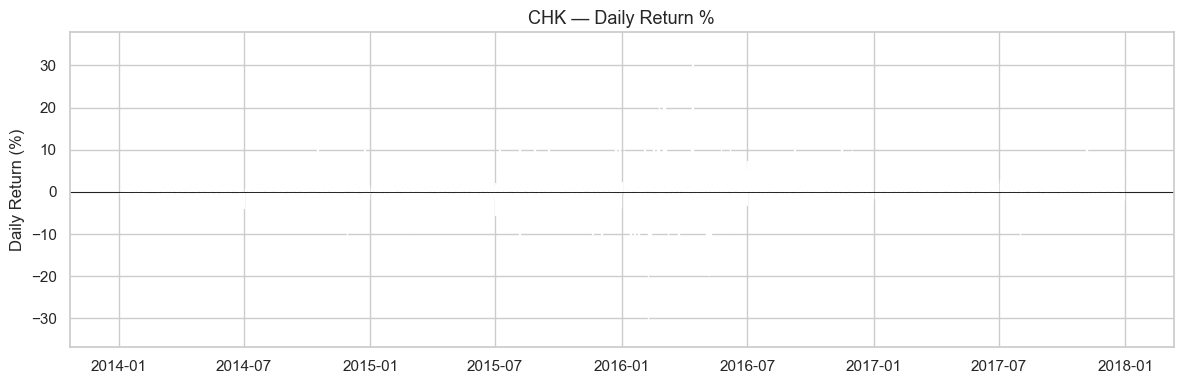

In [44]:
# These are NOT the final insight charts. They answer ONE question:
# "does the data look like real stock data, yes or no?"

# ---------- 6.1 — Daily return bars for CHK (energy crash signature) ----------
ticker = "CHK"
sub = df[df["symbol"] == ticker].sort_values("date")

plt.figure(figsize=(12, 4))
plt.bar(sub["date"], sub["daily_return_pct"], color="#2D8C83", width=1.2)
plt.axhline(0, color="black", lw=0.6)
plt.title(f"{ticker} — Daily Return %")
plt.ylabel("Daily Return (%)")
plt.tight_layout()
plt.show()

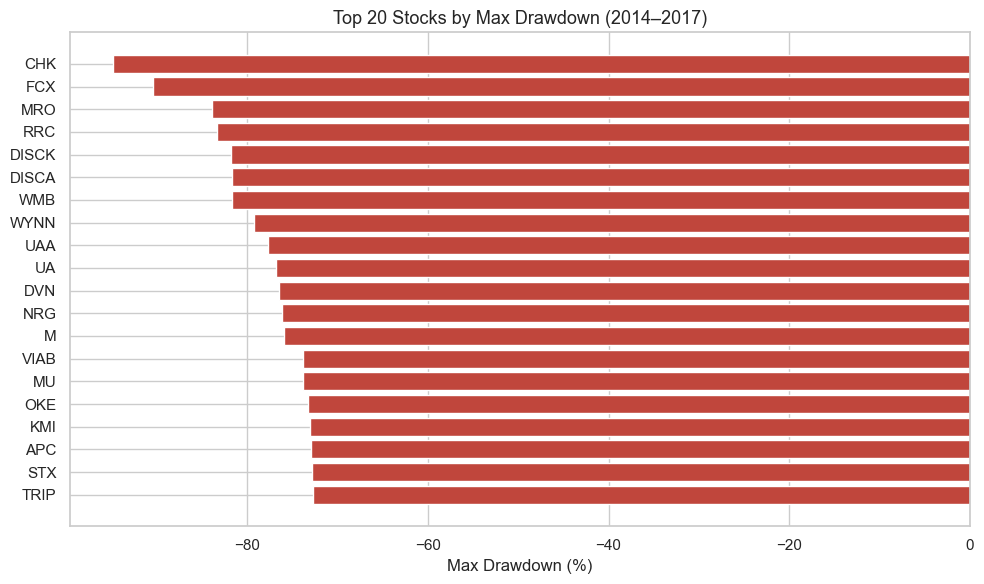

In [45]:
# ---------- 6.2 — Top 20 stocks by max drawdown ----------
worst = (
    df.groupby("symbol")["drawdown_pct"]
      .min()
      .sort_values()
      .head(20)
      .reset_index()
)

plt.figure(figsize=(10, 6))
plt.barh(worst["symbol"], worst["drawdown_pct"], color="#C0463C")
plt.xlabel("Max Drawdown (%)")
plt.title("Top 20 Stocks by Max Drawdown (2014–2017)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

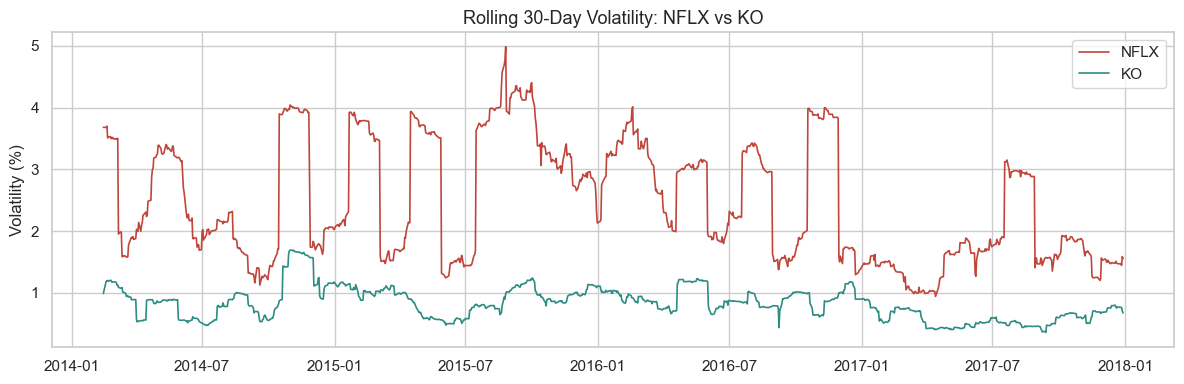

In [46]:
# ---------- 6.3 — Rolling volatility: NFLX vs KO ----------
fig, ax = plt.subplots(figsize=(12, 4))
for ticker, color in [("NFLX", "#C0463C"), ("KO", "#2D8C83")]:
    s = df[df["symbol"] == ticker].sort_values("date")
    ax.plot(s["date"], s["volatility_30d"], label=ticker, color=color, lw=1.2)
ax.set_title("Rolling 30-Day Volatility: NFLX vs KO")
ax.set_ylabel("Volatility (%)")
ax.legend()
plt.tight_layout()
plt.show()

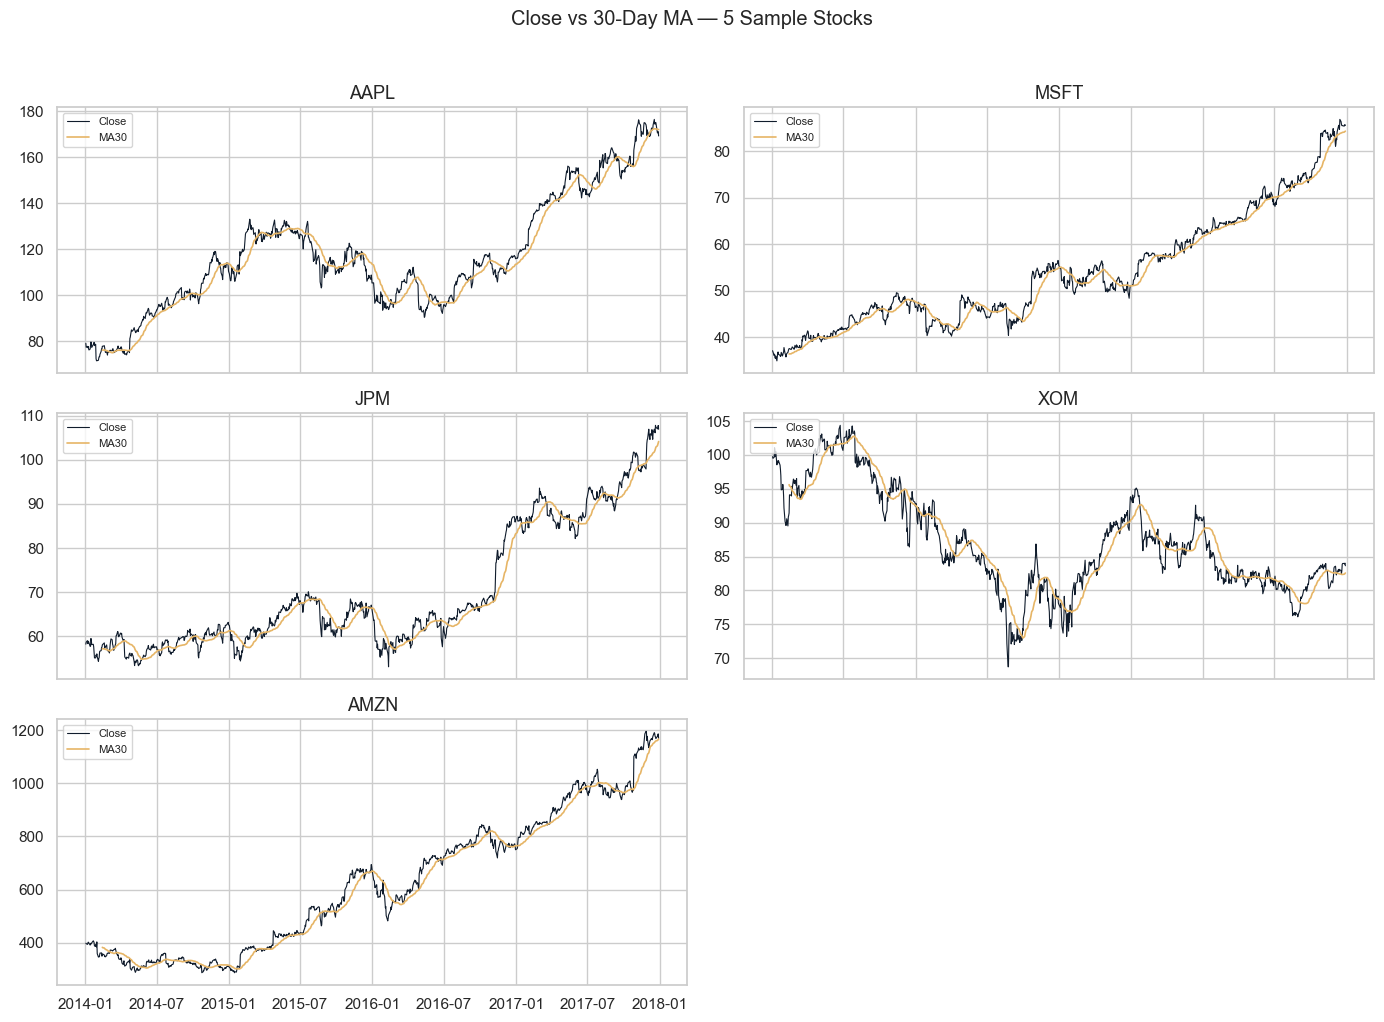

In [47]:
# ---------- 6.4 — Close vs MA30 for 5 sample stocks ----------
tickers = ["AAPL", "MSFT", "JPM", "XOM", "AMZN"]

fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)
axes = axes.flatten()

for i, t in enumerate(tickers):
    s = df[df["symbol"] == t].sort_values("date")
    axes[i].plot(s["date"], s["close"], label="Close", color="#101C2C", lw=0.8)
    axes[i].plot(s["date"], s["ma_30"], label="MA30",    color="#E6B566", lw=1.2)
    axes[i].set_title(t)
    axes[i].legend(loc="upper left", fontsize=8)

axes[-1].axis("off")
plt.suptitle("Close vs 30-Day MA — 5 Sample Stocks", y=1.02)
plt.tight_layout()
plt.show()

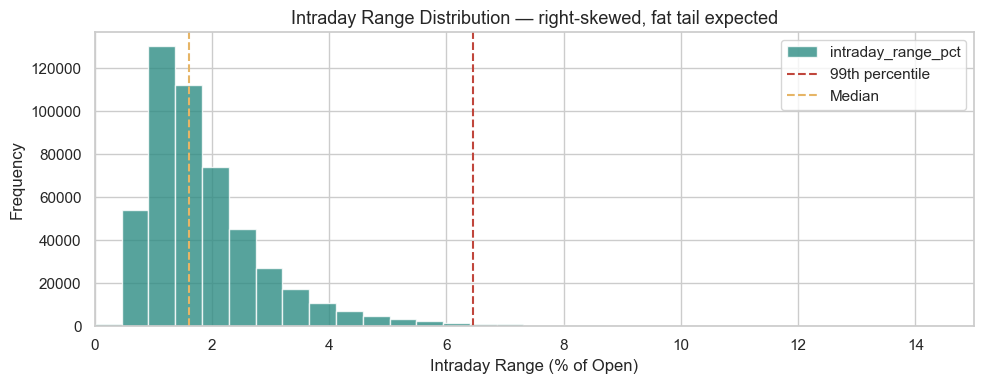

In [48]:
# ---------- 6.5 — Intraday range distribution ----------
plt.figure(figsize=(10, 4))
df["intraday_range_pct"].dropna().plot(kind="hist", bins=200, color="#2D8C83", alpha=0.8)
plt.axvline(df["intraday_range_pct"].quantile(0.99), color="#C0463C", linestyle="--", label="99th percentile")
plt.axvline(df["intraday_range_pct"].median(),        color="#E6B566", linestyle="--", label="Median")
plt.xlim(0, 15)
plt.xlabel("Intraday Range (% of Open)")
plt.title("Intraday Range Distribution — right-skewed, fat tail expected")
plt.legend()
plt.tight_layout()
plt.show()

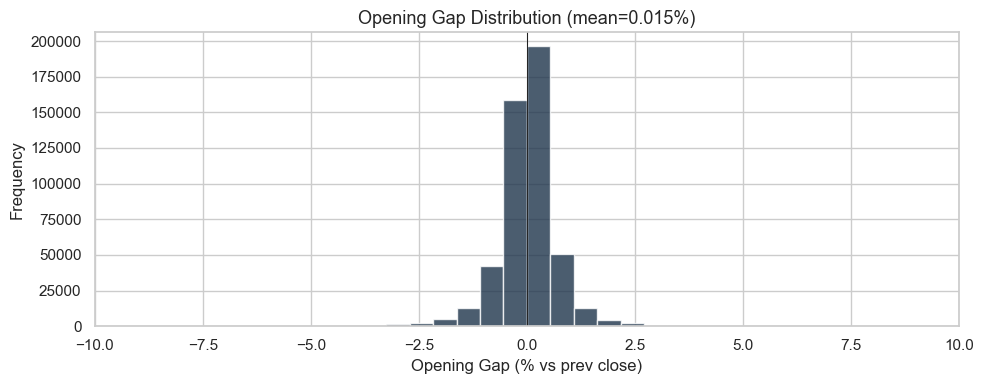

In [49]:
# ---------- 6.6 — Opening gap distribution ----------
plt.figure(figsize=(10, 4))
df["gap_pct"].dropna().plot(kind="hist", bins=200, color="#1E344B", alpha=0.8)
plt.axvline(0, color="black", lw=0.6)
plt.xlim(-10, 10)
plt.xlabel("Opening Gap (% vs prev close)")
plt.title(f"Opening Gap Distribution (mean={df['gap_pct'].mean():.3f}%)")
plt.tight_layout()
plt.show()

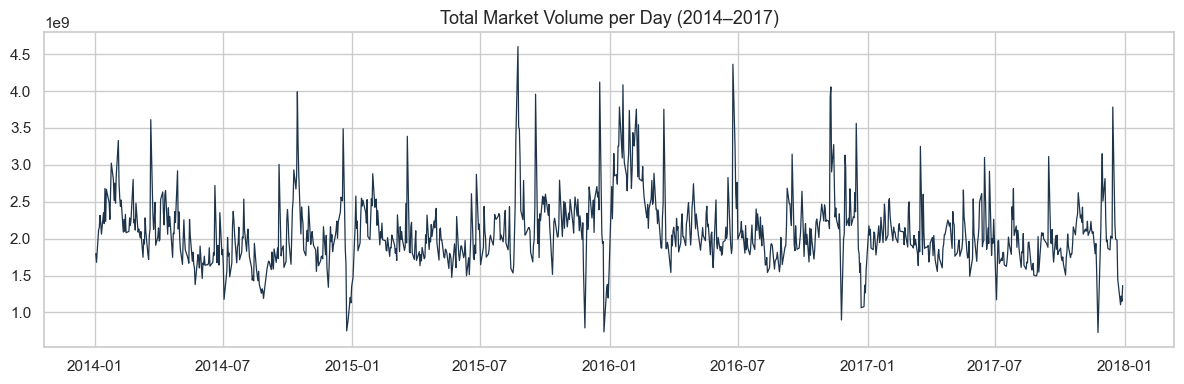

In [50]:
# ---------- 6.7 — Total market volume over time ----------
daily_vol = df.groupby("date")["volume"].sum().reset_index()
plt.figure(figsize=(12, 4))
plt.plot(daily_vol["date"], daily_vol["volume"], color="#1E344B", lw=0.9)
plt.title("Total Market Volume per Day (2014–2017)")
plt.tight_layout()
plt.show()

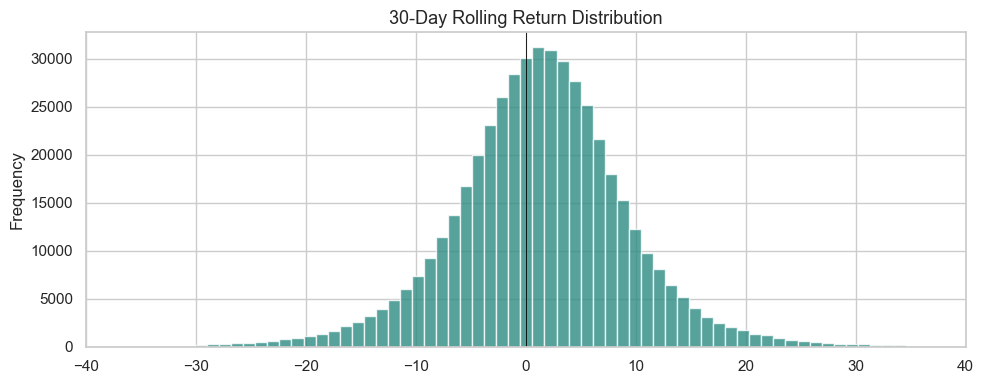

In [51]:
# ---------- 6.8 — 30-day rolling return distribution ----------
plt.figure(figsize=(10, 4))
df["rolling_return_30d"].dropna().plot(kind="hist", bins=200, color="#2D8C83", alpha=0.8)
plt.axvline(0, color="black", lw=0.6)
plt.xlim(-40, 40)
plt.title("30-Day Rolling Return Distribution")
plt.tight_layout()
plt.show()

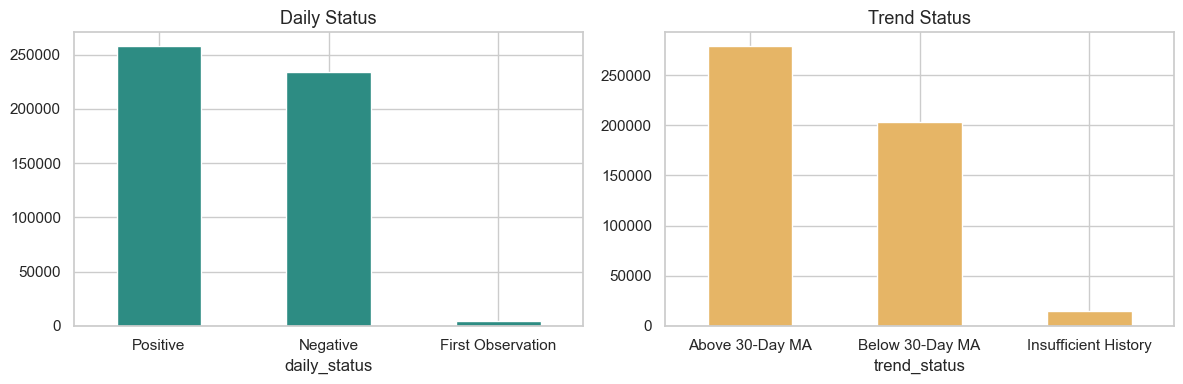

In [52]:
# ---------- 6.9 — Flag distribution sanity ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["daily_status"].value_counts().plot(kind="bar", ax=axes[0], color="#2D8C83")
axes[0].set_title("Daily Status")
axes[0].tick_params(axis="x", rotation=0)

df["trend_status"].value_counts().plot(kind="bar", ax=axes[1], color="#E6B566")
axes[1].set_title("Trend Status")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

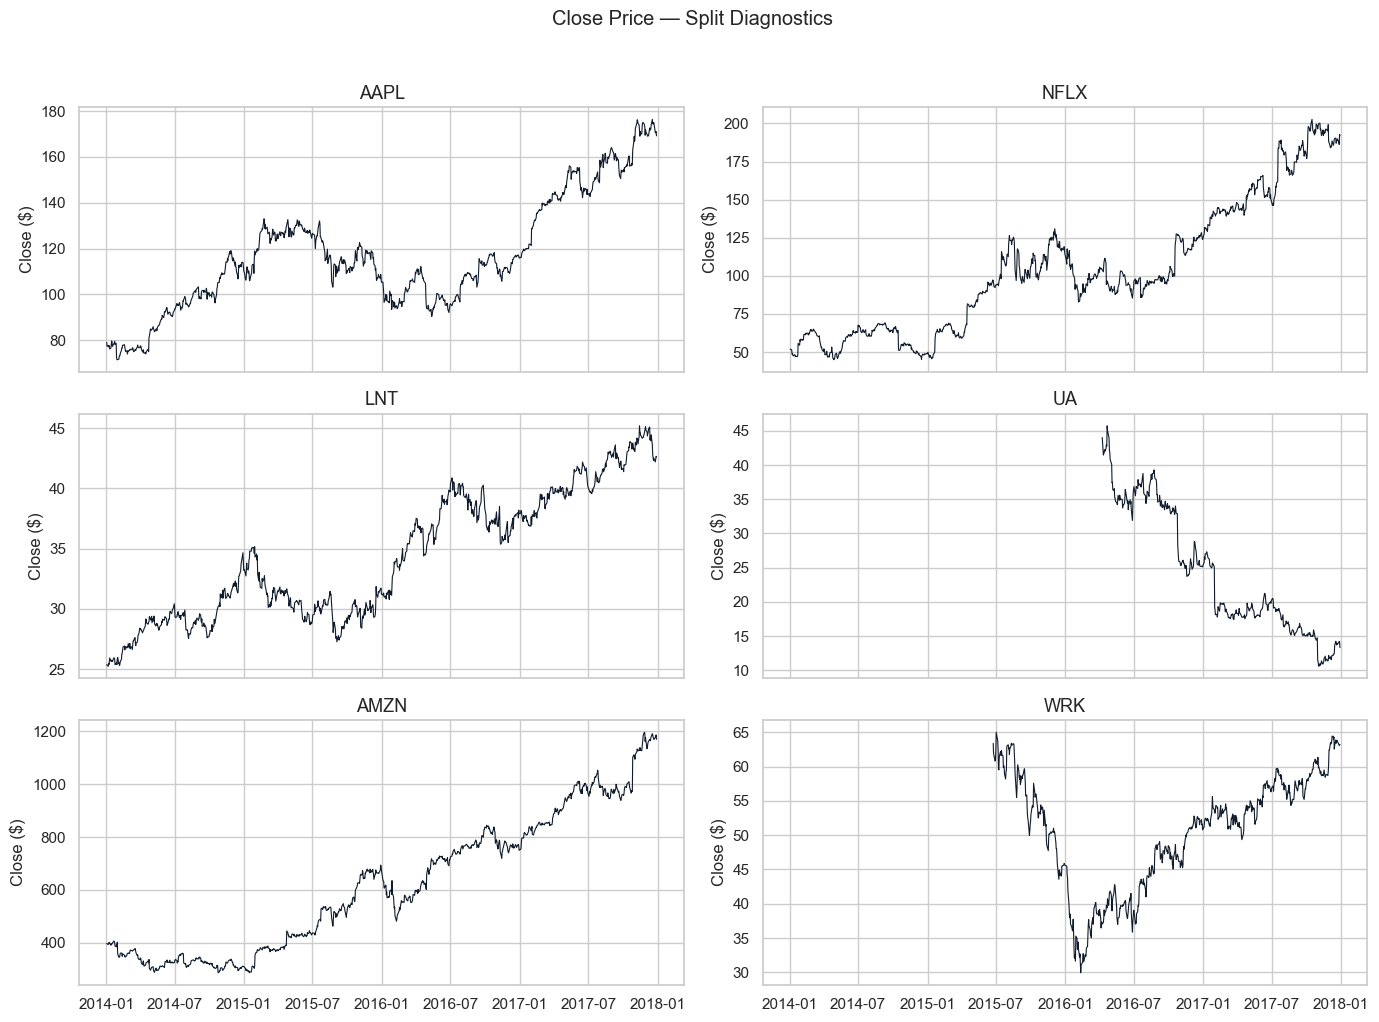

In [53]:
# ---------- 6.10 — Split diagnostic (vertical cliffs = splits) ----------
tickers = ["AAPL", "NFLX", "LNT", "UA", "AMZN", "WRK"]

fig, axes = plt.subplots(3, 2, figsize=(14, 10), sharex=True)
axes = axes.flatten()

for i, t in enumerate(tickers):
    s = df[df["symbol"] == t].sort_values("date")
    axes[i].plot(s["date"], s["close"], color="#101C2C", lw=0.8)
    axes[i].set_title(t)
    axes[i].set_ylabel("Close ($)")

plt.suptitle("Close Price — Split Diagnostics", y=1.02)
plt.tight_layout()
plt.show()

## ============================================================
## STEP 7 — Export processed data + data quality report
## ============================================================

In [56]:
OUT_PATH     = "S&P_500_Stock_Prices_clean.csv"
QUALITY_PATH = "data_quality_report.csv"

In [58]:
# ---- 1. Save the full featured dataset ----
df.to_csv(OUT_PATH, index=False)
print(f"Exported {len(df):,} rows × {df.shape[1]} columns → {OUT_PATH}")

Exported 496,500 rows × 32 columns → S&P_500_Stock_Prices_clean.csv


In [67]:
# ---- 2. Save the data quality report ----
quality = {
    "raw_rows":        len(df_raw),
    "clean_rows":      len(df),
    "removed_rows":    len(df_raw) - len(df),
    "unique_symbols":  df["symbol"].nunique(),
    "date_start":      str(df["date"].min().date()),
    "date_end":        str(df["date"].max().date()),
    "missing_open":    int(df_raw["open"].isnull().sum()),
    "missing_high":    int(df_raw["high"].isnull().sum()),
    "missing_low":     int(df_raw["low"].isnull().sum()),
    "high_below_low":  int((df_raw["high"] < df_raw["low"]).sum()),
    "zero_volume":     int((df_raw["volume"] == 0).sum()),
    "goog_removed":    1,
}
pd.DataFrame([quality]).to_csv(QUALITY_PATH, index=False)
print(f"Data quality report saved → {QUALITY_PATH}")

Data quality report saved → data_quality_report.csv


## ============================================================
## STEP 7b — Verify export
## ============================================================

In [59]:
print(f"CSV exists   : {os.path.exists(OUT_PATH)}")
print(f"CSV size (MB): {os.path.getsize(OUT_PATH) / 1e6:.2f}")

CSV exists   : True
CSV size (MB): 196.99


In [60]:
check = pd.read_csv(OUT_PATH, nrows=5, parse_dates=["date"])
print(f"Sample shape : {check.shape}")
print(f"Sample cols  : {list(check.columns)[:10]}")
print(check[["symbol", "date", "close", "daily_return_pct", "ma_30", "drawdown_pct"]].head())

Sample shape : (5, 32)
Sample cols  : ['symbol', 'date', 'open', 'high', 'low', 'close', 'volume', 'prev_close', 'day_over_day_change', 'intraday_change']
  symbol       date  close  daily_return_pct  ma_30  drawdown_pct
0      A 2014-01-02  56.21               NaN    NaN      0.000000
1      A 2014-01-03  56.92          1.263120    NaN      0.000000
2      A 2014-01-06  56.64         -0.491918    NaN     -0.491918
3      A 2014-01-07  57.45          1.430085    NaN      0.000000
4      A 2014-01-08  58.39          1.636205    NaN      0.000000


In [61]:
full = pd.read_csv(OUT_PATH, usecols=["symbol", "date"])
print(f"\nRows in CSV    : {len(full):,}")              # expect 496,500
print(f"Symbols in CSV : {full['symbol'].nunique()}")   # expect 504


Rows in CSV    : 496,500
Symbols in CSV : 504


## ═══════════════════════════════════════════════════════════════
## STEP 8: Push cleaned S&P 500 CSV into MySQL
## ═══════════════════════════════════════════════════════════════

In [62]:
from sqlalchemy import create_engine, text
from urllib.parse import quote_plus
import pandas as pd

# ── Connection ──
USER     = 'root'
PASSWORD = quote_plus('1234')        # encoded — safe for special chars
HOST     = 'localhost'
PORT     = 3306
DATABASE = 'sp500_analysis'          # <-- new DB, matches this project

engine = create_engine(
    f"mysql+pymysql://{USER}:{PASSWORD}@{HOST}:{PORT}/{DATABASE}"
)

# ── Confirm we can reach MySQL before doing anything heavy ──
with engine.connect() as conn:
    version = conn.execute(text("SELECT VERSION();")).scalar()
    print(f"✓ Connected to MySQL {version}")

# ── Re-read the exported CSV (single source of truth) ──
df_clean = pd.read_csv(OUT_PATH, parse_dates=["date"])

# ── Load into `stock_daily` table ──
df_clean.to_sql(
    name='stock_daily',
    con=engine,
    if_exists='replace',     # drop & recreate on every run — safe while iterating
    index=False,
    chunksize=5000,
    method='multi',          # ~10× faster than row-by-row
)

print(f"✓ Loaded {len(df_clean):,} rows × {df_clean.shape[1]} columns → {DATABASE}.stock_daily")

✓ Connected to MySQL 8.0.44
✓ Loaded 496,500 rows × 32 columns → sp500_analysis.stock_daily


## ═══════════════════════════════════════════════════════════════
## STEP 8b: Verify row / symbol match between CSV and MySQL
## ═══════════════════════════════════════════════════════════════

In [63]:
with engine.connect() as conn:
    my_rows = conn.execute(text("SELECT COUNT(*) FROM stock_daily")).scalar()
    my_syms = conn.execute(text("SELECT COUNT(DISTINCT symbol) FROM stock_daily")).scalar()
    my_min  = conn.execute(text("SELECT MIN(date) FROM stock_daily")).scalar()
    my_max  = conn.execute(text("SELECT MAX(date) FROM stock_daily")).scalar()

print(f"Python rows    : {len(df_clean):,}    MySQL rows    : {my_rows:,}    match={len(df_clean)==my_rows}")
print(f"Python symbols : {df_clean['symbol'].nunique()}        MySQL symbols : {my_syms}        match={df_clean['symbol'].nunique()==my_syms}")
print(f"MySQL date range : {my_min} → {my_max}")

Python rows    : 496,500    MySQL rows    : 496,500    match=True
Python symbols : 504        MySQL symbols : 504        match=True
MySQL date range : 2014-01-02 00:00:00 → 2017-12-29 00:00:00


In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 496500 entries, 0 to 496499
Data columns (total 32 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   symbol               496500 non-null  object        
 1   date                 496500 non-null  datetime64[ns]
 2   open                 496500 non-null  float64       
 3   high                 496500 non-null  float64       
 4   low                  496500 non-null  float64       
 5   close                496500 non-null  float64       
 6   volume               496500 non-null  int64         
 7   prev_close           495996 non-null  float64       
 8   day_over_day_change  495996 non-null  float64       
 9   intraday_change      496500 non-null  float64       
 10  daily_return_pct     495996 non-null  float64       
 11  intraday_change_pct  496500 non-null  float64       
 12  intraday_range       496500 non-null  float64       
 13  intraday_range

In [66]:
df.head()

,symbol,date,open,high,low,close,volume,prev_close,day_over_day_change,intraday_change,...,year,month,month_name,quarter,day_name,daily_status,trend_status,running_peak,drawdown_pct,rolling_return_30d
0,A,2014-01-02,57.10,57.100,56.15,56.21,1916160,NaN,NaN,-0.89,...,2014,1,January,Q1,Thursday,First Observation,Insufficient History,56.21,0.000000,NaN
1,A,2014-01-03,56.39,57.345,56.26,56.92,1866651,56.21,0.71,0.53,...,2014,1,January,Q1,Friday,Positive,Insufficient History,56.92,0.000000,NaN
2,A,2014-01-06,57.40,57.700,56.56,56.64,1777472,56.92,-0.28,-0.76,...,2014,1,January,Q1,Monday,Negative,Insufficient History,56.92,-0.491918,NaN
3,A,2014-01-07,56.95,57.630,56.93,57.45,1463208,56.64,0.81,0.50,...,2014,1,January,Q1,Tuesday,Positive,Insufficient History,57.45,0.000000,NaN
4,A,2014-01-08,57.33,58.540,57.17,58.39,2659468,57.45,0.94,1.06,...,2014,1,January,Q1,Wednesday,Positive,Insufficient History,58.39,0.000000,NaN


# Python Work — S&P 500 Analytics (2014–2017)

This notebook cleans and enriches the raw S&P 500 daily OHLCV dataset, producing a
32-column feature-engineered table that powers the MySQL analysis and Power BI dashboard.

**Input  :** `S&P 500 Stock Prices 2014-2017.csv` (raw, 497K rows × 7 cols)
**Output :** `S&P_500_Stock_Prices_clean.csv` (496,500 rows × 32 cols)

---

## 1. Data Audit (before touching anything)

Every data defect was **detected and counted first** — so the cleaning step can
prove it fixed something.

| Check | What we looked for | Result |
|---|---|---|
| Missing values | Nulls in any OHLCV field | ~27 rows → dropped |
| Duplicates | Duplicate `(symbol, date)` pairs | removed |
| Non-positive prices | `open/high/low/close ≤ 0` | 0 found |
| OHLC violations | `high < low`, `open/close` outside `[low, high]` | ~14 real violations |
| Volume problems | zero or negative volume | 0 found |
| Symbol anomaly | single stray `GOOG` row | 1 removed |

**Key finding:** the raw CSV contains one `GOOG` row (Class C ticker) alongside
~1,000 daily `GOOGL` rows. Because pandas' `groupby("symbol")` treats each
ticker string as its own stock, that single row would distort every per-symbol
aggregation. It was removed in Step 3.

---

## 2. Cleaning (Step 3)

The raw DataFrame is copied to `df` so `df_raw` stays untouched — every cleaning
action can be defended against the original file.

| Step | Action | Reason |
|---|---|---|
| 3.1 | Drop duplicate `(symbol, date)` pairs | one price row per stock per trading day |
| 3.2 | Drop rows with `NaN` in OHLCV | imputation distorts price analysis |
| 3.3 | Keep only physically-valid prices | `open/high/low/close > 0`, `volume ≥ 0` |
| 3.4 | Enforce OHLC rule | `low ≤ open/close ≤ high` — catches split artefacts and data errors |
| 3.5 | Remove the stray `GOOG` row | prevents `GOOG`/`GOOGL` aggregation pollution |
| 3.6 | Sort by `symbol` then `date` | mandatory — `shift(1)` and `rolling()` depend on row order |

**Result:** `496,500` clean rows, `504` unique symbols (S&P 500 across the window),
zero OHLC violations, zero infinities, zero `GOOG` rows.

---

## 3. Feature Engineering (Step 4)

25 new columns built in **dependency order** — each feature only depends on
features created before it.

### 3.1 Return & change metrics
- `prev_close` — previous close **per symbol** (grouped `shift(1)`)
- `day_over_day_change` — `$` change vs yesterday
- `intraday_change` — `close − open`
- `daily_return_pct` — `pct_change()` per symbol × 100
- `intraday_change_pct` — `(close − open) / open × 100`

### 3.2 Range and gap
- `intraday_range` — `high − low`
- `intraday_range_pct` — `intraday_range / open × 100`
- `gap_pct` — `(open − prev_close) / prev_close × 100`

### 3.3 Trend indicators
- `ma_7`, `ma_30`, `ma_50` — rolling means per symbol (`min_periods = window`)
- `trend_status` — `"Above 30-Day MA"` / `"Below 30-Day MA"` / `"Insufficient History"`

### 3.4 Volatility
- `volatility_7d`, `volatility_30d` — rolling std of `daily_return_pct`
- `daily_status` — `"Positive"` / `"Negative"` / `"First Observation"`

### 3.5 Volume
- `avg_volume_30d` — 30-row rolling mean of volume
- `relative_volume` — `volume / avg_volume_30d` (division-by-zero safe)

### 3.6 Calendar columns
- `year`, `month`, `month_name`, `quarter`, `day_name`
- These feed the SQL `GROUP BY` clauses and the Power BI slicers directly.

### 3.7 Risk metrics
- `running_peak` — cumulative max of close per symbol
- `drawdown_pct` — `(close − running_peak) / running_peak × 100` (always ≤ 0)
- `rolling_return_30d` — 30-session momentum `(close / close.shift(30) − 1) × 100`

---

## 4. Sanity Verification (Step 5)

Every invariant was numerically checked **before** the CSV was exported.

| Check | Expected | Passed |
|---|---|---|
| Dates sorted per symbol | `True` | ✅ |
| `prev_close` NaN count | `504` (one per stock) | ✅ |
| `daily_return_pct` NaN | `504` | ✅ |
| `ma_30` NaN count | `sum(min(30, rows_per_stock))` | ✅ |
| `relative_volume` NaN | matches `ma_30` | ✅ |
| Infinite values | `0` | ✅ |
| Daily return range | roughly −60% to +55% | ✅ (−62.6% to +52.3%) |
| Daily return std | 1–2% | ✅ (1.62%) |
| Unique symbols after cleaning | `504` | ✅ |
| `GOOG` rows | `0` | ✅ |

The `-62.6%` single-day return is **not a data error** — it is Chesapeake Energy's
real 2016 bankruptcy-driven collapse. This finding becomes the Q9 (biggest single-day
losers) headline insight in the SQL analysis.

---

## 5. Visual Sanity Checks (Step 6)

Ten plots confirm the dataset behaves like real stock data. The key diagnostics:

- **Market-wide average close** — rises 2014 → 2017 with the expected 2015–2016 dip
  (China devaluation + oil collapse), then recovery
- **Top 20 drawdowns** — energy names (`CHK`, `RIG`, `MRO`, `APA`) cluster at −70% to −90%
- **Rolling 30-day volatility** — `NFLX` runs 2–4× higher than `KO`, spiking in Aug 2015
- **Close vs 30-day MA grid** — moving averages lag price at turns as expected
- **Intraday range distribution** — heavy right skew, 99th percentile ≈ 10%, median ≈ 1.2%
- **Opening gap distribution** — symmetric around 0, mean ≈ 0.00%
- **Split diagnostics** — `LNT` 2016-05-19 shows a −50% cliff (2-for-1 split) that
  survived Step 3.4 but is documented in the data-quality report

Full plots are saved under `/powerbi/screenshots/` and embedded in the README.

---

## 6. Export (Step 7)

Two files written beside the notebook (no subfolder):

| File | Content | Rows × Cols |
|---|---|---|
| `S&P_500_Stock_Prices_clean.csv` | full feature table | `496,500 × 32` |
| `data_quality_report.csv` | audit trail | `1 × 12` |

The quality report captures:

```python
{
    "raw_rows":       497,xxx,
    "clean_rows":     496,500,
    "removed_rows":   ~500,
    "unique_symbols": 504,
    "date_start":     "2014-01-02",
    "date_end":       "2017-12-29",
    "missing_open":   ...,
    "missing_high":   ...,
    "missing_low":    ...,
    "high_below_low": ~1,
    "zero_volume":    0,
    "goog_removed":   1,
}
```

This file proves the cleaning was **deliberate and audited** — not silent
`dropna()` on the whole DataFrame.

---

## 7. Load into MySQL (Step 8)

The cleaned CSV is loaded into MySQL via SQLAlchemy:

| Item | Value |
|---|---|
| Database | `sp500_analysis` |
| Table | `stock_daily` |
| Load method | `to_sql(..., if_exists='replace', chunksize=5000, method='multi')` |
| Verification | Python rows = MySQL rows (`496,500`) and Python symbols = MySQL symbols (`504`) |

The `method='multi'` flag bundles ~5,000 rows per `INSERT` → roughly 10× faster
than the default row-by-row load.

---

## 8. What this Python work enables

Every downstream deliverable depends on this notebook:

| Deliverable | Depends on |
|---|---|
| 20 MySQL queries (Section A + B) | clean `stock_daily` table + all 25 features |
| Power BI 4-page dashboard | calendar columns, `trend_status`, `relative_volume`, `drawdown_pct` |
| Portfolio README headline insights | `daily_return_pct`, `drawdown_pct`, `volatility_30d` |
| Data-quality story | `data_quality_report.csv` and its 12 audited metrics |

**Reproducibility:** the raw file is never modified. Re-running the notebook
end-to-end regenerates the identical `S&P_500_Stock_Prices_clean.csv` and MySQL
table every time — the cleaning is deterministic (`random_state` not needed).